In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score)
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_moons
np.random.seed(42)

In [2]:
url="https://archive.ics.uci.edu/ml/machine-learning-databases/00267/data_banknote_authentication.txt"
columns=["Variance", "Skewness", "Curtosis", "Entropy", "Class"]
df=pd.read_csv(url, header=None, names=columns)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (1372, 5)


,Variance,Skewness,Curtosis,Entropy,Class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


In [3]:
X=df[["Variance", "Skewness"]].values
y=df["Class"].values

X_train, X_test, y_train, y_test=train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 1097
Testing samples: 275


In [4]:
def gini_impurity(y):
    if len(y)==0:
        return 0

    probabilities=np.bincount(y, minlength=2)/len(y)
    return 1-np.sum(probabilities**2)


def entropy(y):
    if len(y)==0:
        return 0

    probabilities=np.bincount(y, minlength=2)/len(y)
    probabilities=probabilities[probabilities>0]

    return -np.sum(probabilities*np.log2(probabilities))

In [5]:
class ManualDecisionTree:
    def __init__(self, criterion="gini", max_depth=5, min_samples_split=2):
        self.criterion=criterion
        self.max_depth=max_depth
        self.min_samples_split=min_samples_split
        self.tree=None

    def impurity(self, y):
        if self.criterion=="gini":
            return gini_impurity(y)
        return entropy(y)

    def best_split(self, X, y):
        best_gain=0
        best_split=None
        parent_impurity=self.impurity(y)

        for feature in range(X.shape[1]):
            thresholds=np.unique(X[:, feature])

            for threshold in thresholds:
                left=X[:, feature] <=threshold
                right=~left

                if not left.any() or not right.any():
                    continue

                n=len(y)
                child_impurity=(left.sum()/n*self.impurity(y[left])+ right.sum()/n*self.impurity(y[right]))
                gain=parent_impurity-child_impurity

                if gain>best_gain:
                    best_gain=gain
                    best_split=(feature, threshold, left, right)
        return best_split

    def build_tree(self, X, y, depth):
        counts=np.bincount(y, minlength=2)
        prediction=int(np.argmax(counts))

        if (len(np.unique(y))==1 or depth>=self.max_depth or len(y)<self.min_samples_split):
            return {"prediction": prediction}

        split=self.best_split(X, y)

        if split is None:
            return {"prediction": prediction}

        feature, threshold, left, right=split
        return {"feature": feature, "threshold": threshold, "prediction": prediction, "left": self.build_tree(X[left], y[left], depth+1),
                "right": self.build_tree(X[right], y[right], depth+1)}

    def fit(self, X, y):
        self.tree=self.build_tree(X, y, 0)
        return self

    def predict_one(self, x, node):
        if "feature" not in node:
            return node["prediction"]

        if x[node["feature"]]<=node["threshold"]:
            return self.predict_one(x, node["left"])

        return self.predict_one(x, node["right"])

    def predict(self, X):
        return np.array([self.predict_one(x, self.tree) for x in X])

In [6]:
manual_tree=ManualDecisionTree( criterion="gini", max_depth=5)

start=time.perf_counter()
manual_tree.fit(X_train, y_train)
tree_train_time=time.perf_counter()-start

start=time.perf_counter()
tree_predictions=manual_tree.predict(X_test)
tree_predict_time=time.perf_counter()-start

print("Manual Tree Accuracy:",accuracy_score(y_test, tree_predictions))
print("Training time:", tree_train_time)
print("Prediction time:", tree_predict_time)

Manual Tree Accuracy: 0.9236363636363636
Training time: 0.3599203080002553
Prediction time: 0.0005429589996310824


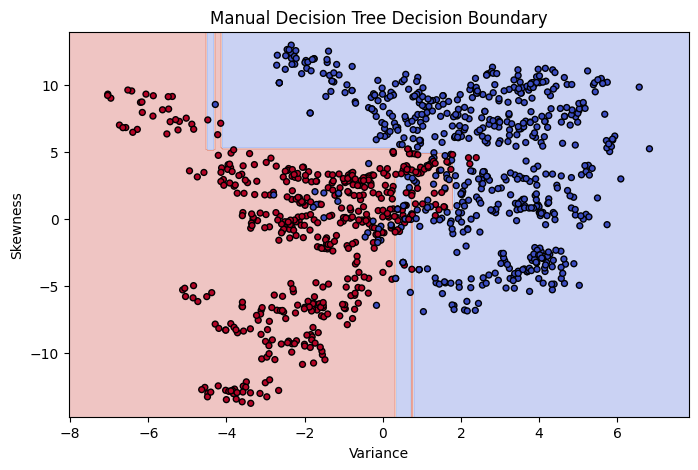

In [7]:
def plot_boundary(model, X, y, title):
    x_min, x_max=X[:, 0].min()-1, X[:, 0].max()+1
    y_min, y_max=X[:, 1].min()-1, X[:, 1].max()+1

    xx, yy=np.meshgrid(np.linspace(x_min, x_max, 250), np.linspace(y_min, y_max, 250))
    grid=np.c_[xx.ravel(), yy.ravel()]
    Z=model.predict(grid).reshape(xx.shape)

    plt.figure(figsize=(8, 5))
    plt.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolors="black", s=18)
    plt.xlabel("Variance")
    plt.ylabel("Skewness")
    plt.title(title)
    plt.show()

plot_boundary(manual_tree, X_train, y_train, "Manual Decision Tree Decision Boundary")

Scikit-learn Tree Accuracy: 0.9309090909090909


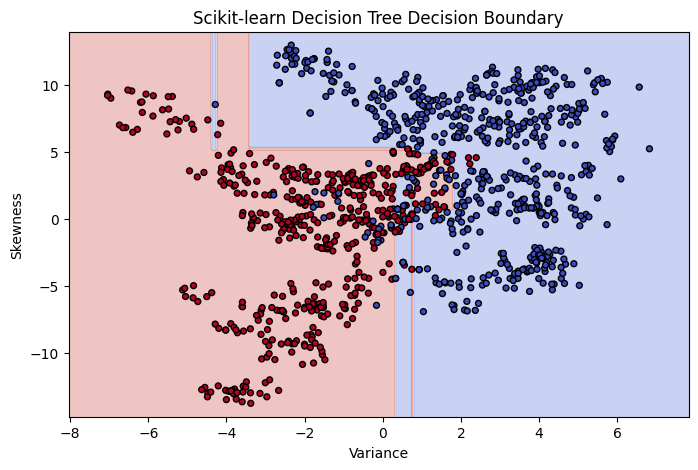

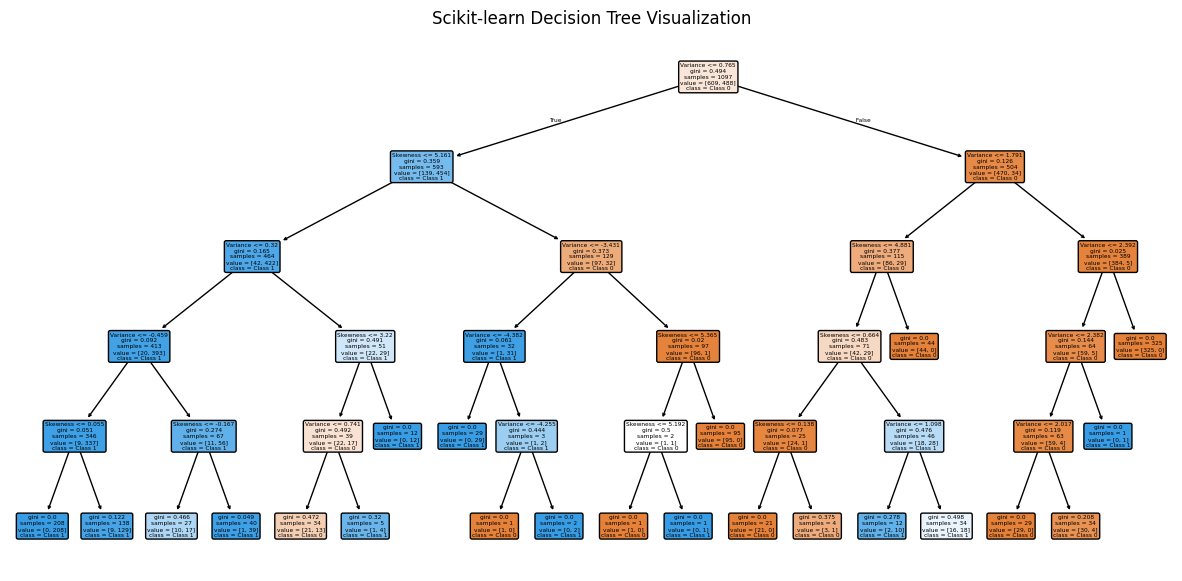

In [8]:
sk_tree=DecisionTreeClassifier(criterion="gini", max_depth=5, random_state=42)

start=time.perf_counter()
sk_tree.fit(X_train, y_train)
sk_tree_train_time=time.perf_counter()-start

start=time.perf_counter()
sk_tree_predictions=sk_tree.predict(X_test)
sk_tree_predict_time=time.perf_counter()-start

print("Scikit-learn Tree Accuracy:", accuracy_score(y_test, sk_tree_predictions))

plot_boundary(sk_tree, X_train, y_train, "Scikit-learn Decision Tree Decision Boundary")

plt.figure(figsize=(15, 7))
plot_tree(sk_tree, feature_names=["Variance", "Skewness"], class_names=["Class 0", "Class 1"], filled=True, rounded=True)
plt.title("Scikit-learn Decision Tree Visualization")
plt.show()

In [9]:
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

y_train_svm=np.where(y_train==1, 1, -1)
y_test_svm=np.where(y_test==1, 1, -1)

In [10]:
class ManualLinearSVM:
    def __init__(self, C=1.0, learning_rate=0.001, iterations=3000):
        self.C=C
        self.learning_rate=learning_rate
        self.iterations=iterations

    def fit(self, X, y):
        n_samples, n_features=X.shape
        self.w=np.zeros(n_features)
        self.b=0.0

        for _ in range(self.iterations):
            margins=y*(X @ self.w+self.b)
            active=margins<1

            grad_w=self.w-(self.C/n_samples)*(X[active].T @ y[active])
            grad_b=-(self.C/n_samples)*np.sum(y[active])

            self.w-=self.learning_rate*grad_w
            self.b-=self.learning_rate*grad_b

        return self

    def decision_function(self, X):
        return X @ self.w+self.b

    def predict(self, X):
        return np.where(self.decision_function(X)>=0, 1, -1)

In [11]:
manual_svm=ManualLinearSVM(C=1.0, learning_rate=0.001, iterations=3000)

start=time.perf_counter()
manual_svm.fit(X_train_scaled, y_train_svm)
svm_train_time=time.perf_counter()-start

start=time.perf_counter()
svm_predictions=manual_svm.predict(X_test_scaled)
svm_predict_time=time.perf_counter()-start

print("Manual SVM Accuracy:",accuracy_score(y_test_svm, svm_predictions))
print("Training time:", svm_train_time)
print("Prediction time:", svm_predict_time)


Manual SVM Accuracy: 0.8727272727272727
Training time: 0.20866539200005718
Prediction time: 0.00014203099999576807


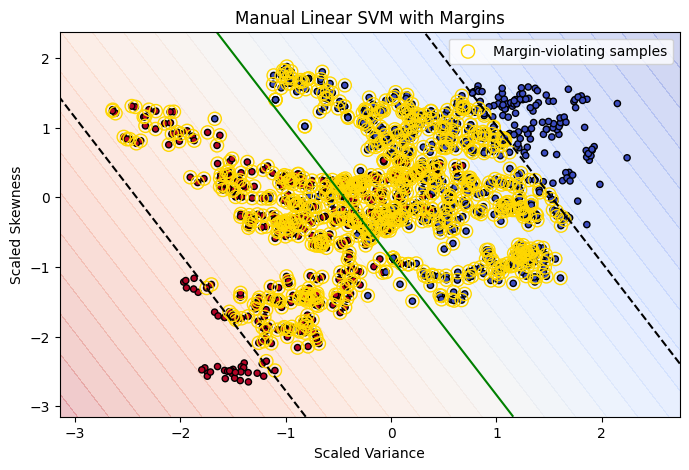

In [12]:
def plot_svm_boundary(model, X, y, title):
    xx, yy=np.meshgrid(np.linspace(X[:, 0].min()-0.5, X[:, 0].max()+0.5, 300), np.linspace(X[:, 1].min()-0.5, X[:, 1].max()+0.5, 300))

    grid=np.c_[xx.ravel(), yy.ravel()]
    scores=model.decision_function(grid).reshape(xx.shape)

    plt.figure(figsize=(8, 5))
    plt.contourf(xx, yy, scores, levels=30,cmap="coolwarm", alpha=0.25)
    plt.contour(xx, yy, scores, levels=[-1, 0, 1], colors=["black", "green", "black"], linestyles=["--", "-", "--"])

    margins=y*model.decision_function(X)<1

    plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolors="black", s=20)
    plt.scatter(X[margins, 0], X[margins, 1], s=90, facecolors="none", edgecolors="gold", label="Margin-violating samples")

    plt.xlabel("Scaled Variance")
    plt.ylabel("Scaled Skewness")
    plt.title(title)
    plt.legend()
    plt.show()

plot_svm_boundary(manual_svm, X_train_scaled, y_train_svm,"Manual Linear SVM with Margins")

Scikit-learn Linear SVM Accuracy: 0.8763636363636363


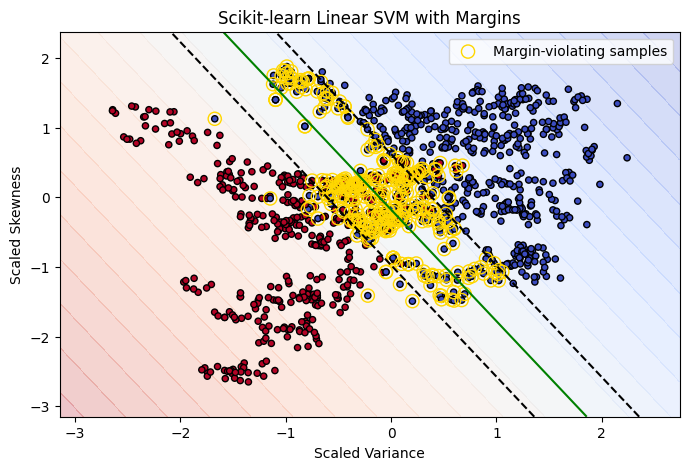

In [13]:
sk_svm=SVC(kernel="linear", C=1.0)
start=time.perf_counter()
sk_svm.fit(X_train_scaled, y_train_svm)
sk_svm_train_time=time.perf_counter()-start

start=time.perf_counter()
sk_svm_predictions=sk_svm.predict(X_test_scaled)
sk_svm_predict_time=time.perf_counter()-start

print("Scikit-learn Linear SVM Accuracy:",accuracy_score(y_test_svm, sk_svm_predictions))

plot_svm_boundary(sk_svm, X_train_scaled, y_train_svm, "Scikit-learn Linear SVM with Margins")

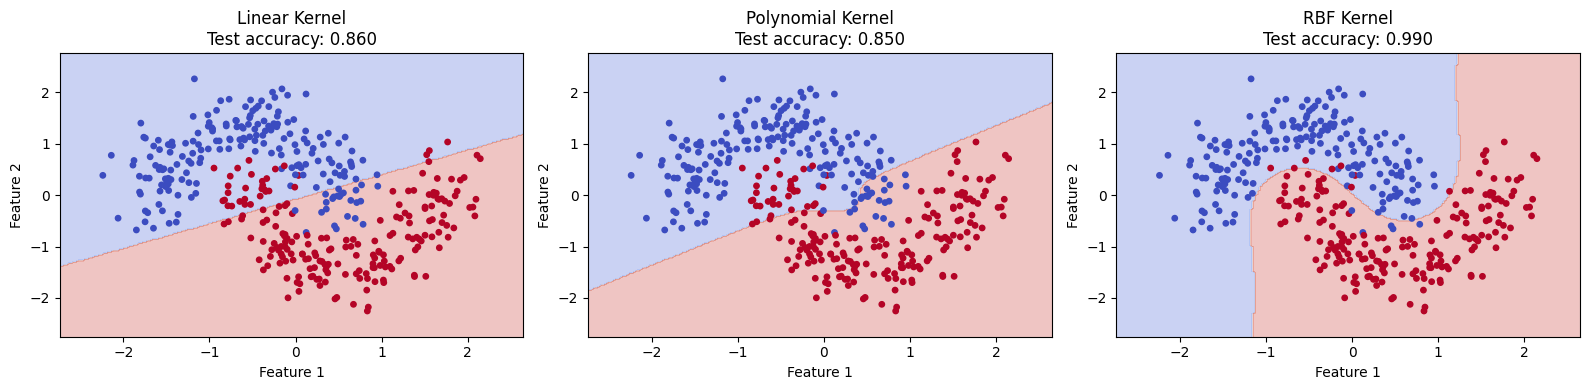

In [14]:
X_moon, y_moon=make_moons(n_samples=500, noise=0.20, random_state=42)
X_moon_train, X_moon_test, y_moon_train, y_moon_test=(train_test_split(X_moon, y_moon, test_size=0.20, random_state=42, stratify=y_moon))
moon_scaler=StandardScaler()
X_moon_train=moon_scaler.fit_transform(X_moon_train)
X_moon_test=moon_scaler.transform(X_moon_test)

kernels={"Linear": SVC(kernel="linear", C=1.0), "Polynomial": SVC(kernel="poly", degree=3, C=1.0), "RBF": SVC(kernel="rbf", C=1.0, gamma="scale")}
fig, axes=plt.subplots(1, 3, figsize=(16, 4))

for ax, (name, model) in zip(axes, kernels.items()):
    model.fit(X_moon_train, y_moon_train)

    xx, yy=np.meshgrid(np.linspace(X_moon_train[:, 0].min()-0.5, X_moon_train[:, 0].max()+0.5, 200),np.linspace(X_moon_train[:, 1].min()-0.5,
                                                                                                                      X_moon_train[:, 1].max()+0.5, 200))

    grid=np.c_[xx.ravel(), yy.ravel()]
    Z=model.predict(grid).reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
    ax.scatter(X_moon_train[:, 0], X_moon_train[:, 1],c=y_moon_train, cmap="coolwarm", s=15)
    ax.set_title(f"{name} Kernel\nTest accuracy: "f"{accuracy_score(y_moon_test, model.predict(X_moon_test)):.3f}")
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")

plt.tight_layout()
plt.show()

In [15]:
X_all=df[["Variance", "Skewness", "Curtosis", "Entropy"]].values
y_all=df["Class"].values
X4_train, X4_test, y4_train, y4_test=train_test_split(X_all, y_all, test_size=0.20, random_state=42, stratify=y_all)

scaler4=StandardScaler()
X4_train_scaled=scaler4.fit_transform(X4_train)
X4_test_scaled=scaler4.transform(X4_test)

y4_train_svm=np.where(y4_train==1, 1, -1)
y4_test_svm=np.where(y4_test==1, 1, -1)

In [16]:
models={"Manual Decision Tree": (ManualDecisionTree(criterion="gini", max_depth=5), X4_train, X4_test, y4_train, y4_test),
          "Sklearn Decision Tree": (DecisionTreeClassifier(max_depth=5, random_state=42), X4_train, X4_test, y4_train, y4_test),
          "Manual Linear SVM": (ManualLinearSVM(C=1.0, learning_rate=0.001, iterations=3000), X4_train_scaled, X4_test_scaled, y4_train_svm, y4_test_svm),
          "Sklearn Linear SVM": (SVC(kernel="linear", C=1.0), X4_train_scaled, X4_test_scaled, y4_train_svm, y4_test_svm),
          "Sklearn RBF SVM": (SVC(kernel="rbf", C=1.0, gamma="scale"), X4_train_scaled, X4_test_scaled, y4_train_svm, y4_test_svm)}

In [17]:
results=[]

for name, (model, Xtr, Xte, ytr, yte) in models.items():
    start=time.perf_counter()
    model.fit(Xtr, ytr)
    train_time=time.perf_counter()-start
    start=time.perf_counter()
    predictions=model.predict(Xte)
    predict_time=time.perf_counter()-start

    results.append({"Model": name, "Accuracy": accuracy_score(yte, predictions), "Precision": precision_score(yte, predictions, zero_division=0),
                    "Recall": recall_score(yte, predictions, zero_division=0), "F1-score": f1_score(yte, predictions, zero_division=0), "Training time (s)": train_time,
                    "Prediction time (s)": predict_time})

results_df=pd.DataFrame(results)
display(results_df.round(5))

,Model,Accuracy,Precision,Recall,F1-score,Training time (s),Prediction time (s)
0,Manual Decision Tree,0.98182,0.98347,0.97541,0.97942,0.78870,0.00060
1,Sklearn Decision Tree,0.99273,0.98387,1.00000,0.99187,0.00525,0.00033
2,Manual Linear SVM,0.88000,0.91589,0.80328,0.85590,0.21037,0.00003
3,Sklearn Linear SVM,0.97455,0.94574,1.00000,0.97211,0.00852,0.00078
4,Sklearn RBF SVM,1.00000,1.00000,1.00000,1.00000,0.00565,0.00163


In [18]:
plt.savefig("plot_name.png", dpi=200, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

In [19]:
results_df.to_csv("model_comparison.csv", index=False)